**Questions - (1):**<br>
<br>
For this, I used a small subset of the CelebA face dataset and prepared the images for a diffusion model. I resized the images, applied basic preprocessing,created a DataLoader and used a DDPM scheduler to add noise at different timesteps.I also comapred schedular-based noise with simple linear noise addition.

In [2]:
#To check if required libraries are already installed

try:
    import diffusers
    import datasets
    import torchvision
    import matplotlib
    import accelerate

    print("All required libraries are already installed.")

except ImportError:
    print("Installing required libraries")
    !pip install diffusers datasets torchvision matplotlib accelerate

All required libraries are already installed.


In [6]:
# Step 1: Import required libraries

import torch
import torchvision.transforms as transforms
from datasets import load_dataset
from torch.utils.data import DataLoader
from diffusers import DDPMScheduler
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device being used:", device)

Device being used: cpu


Step-(1):<br>
I loaded the first 1000 images from the CelebA faces dataset.Then I used a smaller subset because it is easier to preocess and enough for understanding the forward diffusion process.

In [4]:
#Loading a small face dataset

dataset = load_dataset("nielsr/CelebA-faces", split="train[:1000]")

print("The Dataset has been loaded successfully")
print(dataset)

dataset_infos.json:   0%|          | 0.00/667 [00:00<?, ?B/s]

data/train-00000-of-00003.parquet:   0%|          | 0.00/462M [00:00<?, ?B/s]

data/train-00001-of-00003.parquet:   0%|          | 0.00/463M [00:00<?, ?B/s]

data/train-00002-of-00003.parquet:   0%|          | 0.00/463M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/202599 [00:00<?, ? examples/s]

The Dataset has been loaded successfully
Dataset({
    features: ['image'],
    num_rows: 1000
})


Step - (2):<br>
- The images are resized to 64×64 pixels
- Randomly flipped horizontally
- Converted into tensors
- Normalized to the range [-1,1]<br>
This prepares the images for the difuusion process





In [5]:
#Preprocessing the images

preprocess = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

def transform_images(examples):
    examples["image"] = [
        preprocess(img.convert("RGB")) for img in examples["image"]
    ]
    return examples

dataset.set_transform(transform_images)

print("Preprocessing is applied successfully")

Preprocessing is applied successfully


Step-(3):<br>
I created a DataLoader with a batch size of 16.This allows the images to be loaded in small batches instead of preprocessing the entire dataset at once.


In [6]:
#DataLoader creation

dataloader = DataLoader(
    dataset,
    batch_size=16,
    shuffle=True
)

batch = next(iter(dataloader))
images = batch["image"][:8]

print("Batch shape:", batch["image"].shape)
print("Selected images shape:", images.shape)

Batch shape: torch.Size([16, 3, 64, 64])
Selected images shape: torch.Size([8, 3, 64, 64])


Step-(4):<br>
Before adding noise, I displayed 8 preprocessed face images to confirm that the images were loaded and transformed correctly.

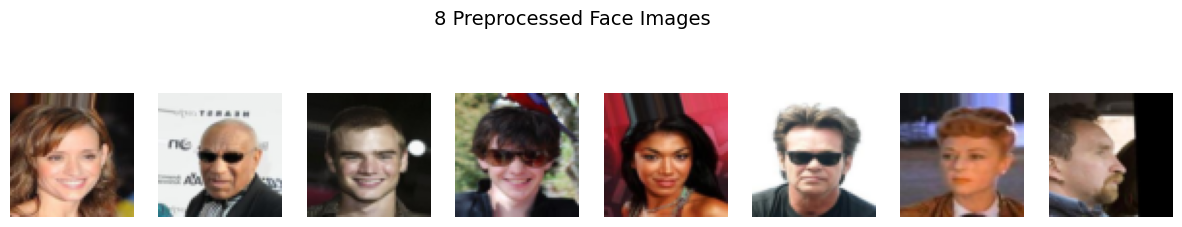

In [8]:
#Displaying 8 preprocessed images

def show_images(imgs, title):
    fig, axes = plt.subplots(1, len(imgs), figsize=(15, 3))
    fig.suptitle(title, fontsize=14)

    for i, ax in enumerate(axes):
        img = (imgs[i] / 2 + 0.5).clamp(0, 1)
        img = img.permute(1, 2, 0).cpu().numpy()

        ax.imshow(img)
        ax.axis("off")

    plt.show()

show_images(images, "8 Preprocessed Face Images")

Step-(5):<br>
I created a DDPM scheduler with 1000 training timesteps.The scheduler controls how noise is added to the image during the forward diffusion process.

In [9]:
#Creating the DDPMScheduler

scheduler = DDPMScheduler(
    num_train_timesteps=1000,
    beta_start=0.001,
    beta_end=0.02
)

print("DDPM Scheduler created successfully")
print("Number of timesteps:", scheduler.config.num_train_timesteps)

DDPM Scheduler created successfully
Number of timesteps: 1000


Step-(6):<br>
I added noise to eight images using different timesteps.Lower timesteps add less noise, while higher timesteps make the image much harder to recognize.

In [10]:
#Adding noise to 8 images using different timesteps

noise = torch.randn_like(images)

timesteps = torch.tensor(
    [0, 142, 285, 428, 570, 713, 856, 999],
    dtype=torch.long
)

noisy_images = scheduler.add_noise(images, noise, timesteps)

print("Original images shape:", images.shape)
print("Noise shape:", noise.shape)
print("Noisy images shape:", noisy_images.shape)
print("Timesteps used:", timesteps.tolist())

Original images shape: torch.Size([8, 3, 64, 64])
Noise shape: torch.Size([8, 3, 64, 64])
Noisy images shape: torch.Size([8, 3, 64, 64])
Timesteps used: [0, 142, 285, 428, 570, 713, 856, 999]


Step-(7):<br>
The below images show how the same preprocessing batch changes as different levels of noise are added using the scheduler.

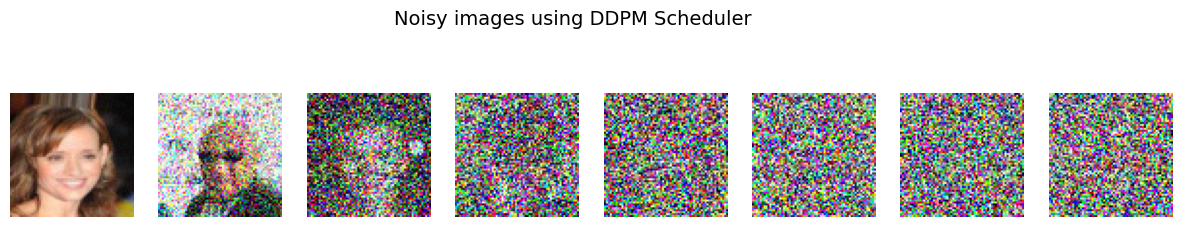

In [11]:
#Displaying the noisy images

show_images(noisy_images, "Noisy images using DDPM Scheduler")

Step-(8):<br>
In this step,I compared the DDPM scheduler noise with a simple linear noise addition method.This helps to show why diffusion models use a planned noise schedule instead of directly mixing images with random noise.

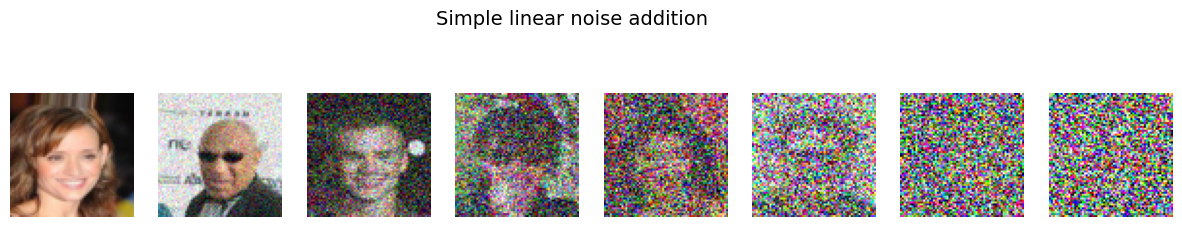

In [12]:
def simple_corrupt(x, noise, amount):
    return (1 - amount) * x + amount * noise

simple_noisy_images = []

amounts = torch.linspace(0, 1, 8)

for i in range(8):
    corrupted = simple_corrupt(images[i], noise[i], amounts[i])
    simple_noisy_images.append(corrupted)

simple_noisy_images = torch.stack(simple_noisy_images)

show_images(simple_noisy_images, "Simple linear noise addition")

**Reflection:** <br>

(a)As the timestep increases,the face images gradually become noisier and lose their original details. At smaller timesteps,the facial features are still clear because only a small amount of noise is added.As the timestep gets larger,the image becomes more distorted,and by the final timestep, the face is almost completely hidden by random noise.
<br>
(b)The images are normalized to the range[-1, 1] because diffusion models usually work better when the input values are centered around zero. This also helps match the image values with the Gaussian noise that is added during the diffusion process.
<br>
(c)Scheduler-based noise is different from simple noise addition because the scheduler follows a planned noise schedule. It carefully controls how much noise is added at each timestep. Simple noise addition only blends the image and random noise directly,so it does not follow the same mathematical process used in diffusion models.
<br>
(d)The values beta_start and beta_end control the amount of noise added during the diffusion process. beta_start controls the noise level at the beginning, while beta_end controls the noise level near the end. Together,they decide how slowly or quickly the image becomes noisy.

**Question-(2):** <br>

For this,I built a UNet model for 64×64 RGB face images.The goal is to train the model to predict the noise added by the DDPM scheduler.This is an important step in diffusion models because the model learns how to remove noise during the reverse diffusion process.

In [3]:
#Importing the extra libraries that are required

import torch.nn.functional as F
from diffusers import UNet2DModel
from tqdm.auto import tqdm

print("The required libraries imported successfully")

The required libraries imported successfully


Step-(1):<br>
I created a UNet2DModel for 64×64 RGB images.Since the input image has 3 color channels,the model input and output channels are both set to 3.

In [7]:
model = UNet2DModel(
    sample_size=64,
    in_channels=3,
    out_channels=3,
    layers_per_block=2,
    block_out_channels=(64, 128, 128, 256),
    down_block_types=(
        "DownBlock2D",
        "DownBlock2D",
        "AttnDownBlock2D",
        "DownBlock2D"
    ),
    up_block_types=(
        "UpBlock2D",
        "AttnUpBlock2D",
        "UpBlock2D",
        "UpBlock2D"
    )
).to(device)

print("UNet model created successfully")

UNet model created successfully


Step-(2):<br>
I selected a small batch of images,added random noise using the scheduler and passed the noisy images into the UNet model.

In [10]:
#Passing noisy images into the UNet

if "dataloader" not in globals():
    if "dataset" not in globals():
        dataset = load_dataset("nielsr/CelebA-faces", split="train[:1000]")
    dataloader = DataLoader(dataset, batch_size=16, shuffle=True)

batch = next(iter(dataloader))
sample_images = batch["image"][:8].to(device)

sample_noise = torch.randn_like(sample_images)

sample_timesteps = torch.randint(
    0,
    scheduler.config.num_train_timesteps,
    (sample_images.shape[0],),
    device=device
).long()

sample_noisy_images = scheduler.add_noise(
    sample_images,
    sample_noise,
    sample_timesteps
)

with torch.no_grad():
    sample_noise_prediction = model(
        sample_noisy_images,
        sample_timesteps
    ).sample

print("Noisy images were passed through the UNet")

TypeError: default_collate: batch must contain tensors, numpy arrays, numbers, dicts or lists; found <class 'PIL.JpegImagePlugin.JpegImageFile'>

Step-(3):<br>
The noisy input and predicted noise output should have the same shape.This confirms that the model is predicting one noise value for every pixel and channel in the image.

In [16]:
print("Shape of noisy input:", sample_noisy_images.shape)
print("Shape of predicted noise output:", sample_noise_prediction.shape)

Shape of noisy input: torch.Size([8, 3, 64, 64])
Shape of predicted noise output: torch.Size([8, 3, 64, 64])


Step-(4):<br>
For training,each image in the batch receives a randomly selected timestep.This helps the model learn to predict noise at different stages of the diffusion process.

In [17]:
# step (4)
train_batch = next(iter(dataloader))
clean_images = train_batch["image"].to(device)

batch_size = clean_images.shape[0]

random_timesteps = torch.randint(
    0,
    scheduler.config.num_train_timesteps,
    (batch_size,),
    device=device
).long()

print("Batch size:", batch_size)
print("Random timesteps shape:", random_timesteps.shape)
print("First few random timesteps:", random_timesteps[:8])

Batch size: 16
Random timesteps shape: torch.Size([16])
First few random timesteps: tensor([442, 657, 600, 359, 681, 348, 694, 543])


Step-(5):<br>
Using the randomly selected timesteps,I added Gaussian noise to the clean images.Images with higher timesteps receive more noise.

In [18]:
#Step (5)

actual_noise = torch.randn_like(clean_images)

noisy_train_images = scheduler.add_noise(
    clean_images,
    actual_noise,
    random_timesteps
)

print("Clean images shape:", clean_images.shape)
print("Actual noise shape:", actual_noise.shape)
print("Noisy images shape:", noisy_train_images.shape)

Clean images shape: torch.Size([16, 3, 64, 64])
Actual noise shape: torch.Size([16, 3, 64, 64])
Noisy images shape: torch.Size([16, 3, 64, 64])


Step-(6):<br>
The noisy images and their timesteps are passed into the UNet.The model predicts the noise that was added to each image.

In [19]:
#Step(6)

noise_pred = model(
    noisy_train_images,
    random_timesteps
).sample

print("Predicted noise shape:", noise_pred.shape)

Predicted noise shape: torch.Size([16, 3, 64, 64])


Step-(7):<br>
The ε-objective loss compares the model's predicted noise with the actual noise. <br>
I used mean squared error because the model is learning to make its prediction as close as possible to the real noise.

In [20]:
# Step-(7)

loss = F.mse_loss(noise_pred, actual_noise)

print("Initial MSE loss:", loss.item())

Initial MSE loss: 1.1925629377365112


Step-(8):<br>
I trained the UNet model for 5 epochs using the AdamW optimizer.In each batch,random timesteps and random noise were used so that the model could learn different noise levels.

In [21]:
#Step-(8)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4
)

epochs = 5
loss_history = []

model.train()

for epoch in range(epochs):
    total_loss = 0

    for batch in tqdm(dataloader, desc=f"Epoch {epoch + 1}/{epochs}"):

        clean_images = batch["image"].to(device)
        batch_size = clean_images.shape[0]

        timesteps = torch.randint(
            0,
            scheduler.config.num_train_timesteps,
            (batch_size,),
            device=device
        ).long()

        noise = torch.randn_like(clean_images)

        noisy_images = scheduler.add_noise(
            clean_images,
            noise,
            timesteps
        )

        noise_prediction = model(
            noisy_images,
            timesteps
        ).sample

        loss = F.mse_loss(
            noise_prediction,
            noise
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(dataloader)
    loss_history.append(average_loss)

    print("Epoch", epoch + 1, "Average Loss:", round(average_loss, 4))

Epoch 1/5:   0%|          | 0/63 [00:00<?, ?it/s]

: 

Step-(9):<br>
I stored the average loss from each epoch and plotted it as a line graph. This helps show whether the model is learning during training.

In [ ]:
#Step-(9)

plt.figure(figsize=(7, 5))
plt.plot(range(1, epochs + 1), loss_history, marker="o")
plt.title("UNet Training Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Average MSE Loss")
plt.grid(True)
plt.show()

**Reflection:**<br>
<br>
(a)The UNet output must have the same shape as the input because the model is predicting the noise added to every pixel of the image. Since the input image has three color channels and a 64 × 64 size, the predicted noise must also have the same dimensions. Otherwise, it cannot be compared correctly with the actual noise.<br>

(b)The model predicts noise ε instead of directly predicting the clean image because noise prediction is a simpler and more steady training target. The diffusion process adds known Gaussian noise, so the model is trained to estimate that noise at different timesteps. Once the noise is predicted, it can be removed step by step during image generation.<br>

(c)The loss curve can be noisy because every batch uses random images, random timesteps, and random noise. Some timesteps are easier to learn because the image is still clear, while later timesteps are harder because the image is almost fully noisy.<br>

(d)Even if the loss decreases, visual inspection is still important. A lower numerical loss does not always mean the generated images look realistic. The model may reduce error mathematically but still produce blurry faces, distorted features, or unnatural colors. Therefore, both the loss curve and the generated image quality should be checked.<br>

**Question-(3):**<br>
In this question, I generated images using two approaches.First, I used my trained UNet model to start from random Gaussian noise and gradually denoise it. Then, I used a pretrained diffusion model and compared generated images using 20, 50, and 100 denoising steps.

In [1]:
#Importing the diffusion pipeline used for pretrained generation

from diffusers import DDPMPipeline

print("Required libraries imported successfully")

Required libraries imported successfully


**Part-A: Generating images with my trained Model:**<br>
In this part,I used the UNet model trained in Question 2.The generation process starts with random Gaussian noise and uses the scheduler to remove noise step by step.

Part A.(1): I created four random Gaussian noise images with the shape 4×3×64×64.These act as the starting point for image generation

In [2]:
# Part A.(1)

model.eval()

sample = torch.randn(4, 3, 64, 64).to(device)

print("Starting sample shape:", sample.shape)

NameError: name 'model' is not defined

Part A.(2):<br>
The scheduler runs backward from noisy images to cleaner images.At each timestep,the UNet predicts the noise and the scheduler uses that prediction to update the image.

In [ ]:
# Part A.(2)

early_stage = None
middle_stage = None
final_stage = None

scheduler.set_timesteps(1000)

for step_index, timestep in enumerate(tqdm(scheduler.timesteps, desc="Generating images with trained model")):

    with torch.no_grad():
        noise_prediction = model(sample, timestep).sample

    sample = scheduler.step(
        noise_prediction,
        timestep,
        sample
    ).prev_sample

    # Save images from different denoising stages
    if step_index == 100:
        early_stage = sample.clone()
    elif step_index == 500:
        middle_stage = sample.clone()
    elif step_index == 999:
        final_stage = sample.clone()

print("Image generation using trained model completed")

<br>
Part A.(3):The final output contains four generated images from the trained model.Since the model was trained only for a small number of epochs, the results may not look as realistic as a pretrained diffusion model.

In [ ]:
print("Final generated image batch shape:", final_stage.shape)
print("Number of generated images:", final_stage.shape[0])

<br>
Part A.(4):I saved and displayed images from the early,middle and final denoising stages to show how the generated samples changed during reverse diffusion.

In [ ]:
#Part A.(4)

show_images(early_stage.cpu(), "Early Denoising Stage")
show_images(middle_stage.cpu(), "Middle Denoising Stage")
show_images(final_stage.cpu(), "Final Generated Images from Trained Model")

<br>

Part-B.(1): I loaded the pretrained CelebA-HQ DDPM model from Hugging Face.This model is used to compare the results from my trained model with a stronger pretrained diffusion model.

In [ ]:
#Loading pre-trained diffusion model

from diffusers import DDPMPipeline

pretrained_pipeline = DDPMPipeline.from_pretrained(
    "google/ddpm-celebahq-256"
).to(device)

print("Pretrained diffusion model loaded successfully")

<br>
Part-B.(2): First,I generated face images using 20 denoising steps.This uses fewer reverse diffusion steps,so the model has less time to refine the image.

In [ ]:
#Generating images with 20 inference steps

images_20 = pretrained_pipeline(
    batch_size=4,
    num_inference_steps=20
).images

print("Generated 4 images using 20 denoising steps")

<br>
Part-B.(2): Next, I generated face images using 50 denoising steps.This gives the model more steps to remove noise and improve the generated image quality.

In [ ]:
#Generating images with 50 inference steps

images_50 = pretrained_pipeline(
    batch_size=4,
    num_inference_steps=50
).images

print("Generated 4 images using 50 denoising steps")


<br>
Part-B.(2):
Finally, I generated face images using 100 denoising steps. More steps usually allow the model to make smaller corrections during generation.

In [ ]:
#Generating images with 100 inference steps

images_100 = pretrained_pipeline(
    batch_size=4,
    num_inference_steps=100
).images

print("Generated 4 images using 100 denoising steps")

<br>
Part-B.(3): I displayed the generated images side by side, from 20, 50 and 100 denoising steps so that the quality of the outputs can be compared visually.

In [ ]:
#Function to display generated PIL images

def show_pil_images(imgs, title):
    fig, axes = plt.subplots(1, len(imgs), figsize=(15, 3))
    fig.suptitle(title, fontsize=14)

    for i, ax in enumerate(axes):
        ax.imshow(imgs[i])
        ax.axis("off")

    plt.show()

In [ ]:
#Displaying generated images side by side

show_pil_images(images_20, "Pretrained Model: 20 Denoising Steps")
show_pil_images(images_50, "Pretrained Model: 50 Denoising Steps")
show_pil_images(images_100, "Pretrained Model: 100 Denoising Steps")

In [ ]:
# combined display
# Display one row for each denoising step count

all_results = [
    ("20 Steps", images_20),
    ("50 Steps", images_50),
    ("100 Steps", images_100)
]

for title, imgs in all_results:
    show_pil_images(imgs, title)

**Reflection:**<br>
<br>
(a)Image generation begins with random Gaussian noise because diffusion models are trained to remove noise from images one step at a time. During training, clean images are gradually made noisier. When creating a new image, the model starts with random noise and gradually produces a clear face.<br>

(b)The scheduler controls the reverse diffusion process. It chooses how much noise to remove at each step and updates the image bit by bit. The UNet predicts the noise, and the scheduler uses this information to make the image clearer with each step.<br>

(c)With more denoising steps, images tend to look clearer and show more details. If there are fewer steps, some noise might remain, making the images look blurry or less realistic. Taking more steps helps the model create better images.<br>

(d)Diffusion models need many denoising steps because they build images slowly, removing a bit of noise at each stage. GANs work differently, creating a whole image at once using a generator network. GANs are much faster, but diffusion models often produce more stable and realistic images because they refine them in a step-by-step manner.<br>

